# CNN phân loại ảnh X-ray: NORMAL và PNEUMONIA

Chạy từng ô từ trên xuống bằng **Shift + Enter**, hoặc chọn **Restart Kernel and Run All Cells**.
Notebook viết trực tiếp các bước: dữ liệu → Dataset → DataLoader → CNN → train → đánh giá → dự đoán.
Không có hàm phụ hay `main()`; chỉ Dataset cần ba phương thức để PyTorch đọc ảnh.

Đây là bài tập học CNN từ đầu, phục vụ học tập, không phải công cụ chẩn đoán.

## 1. Import thư viện và cấu hình

Chọn kernel Python đã cài thư viện trong `requirements.txt`.
Sửa `batch_size`, `learning_rate` bên dưới; số `epochs` được đặt ở ô train.
Mở Jupyter từ thư mục project để đường dẫn `data/` hoạt động.

In [1]:
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

data_dir = Path("data/archive/xray_dataset_covid19")
output_dir = Path("outputs/notebook")
output_dir.mkdir(parents=True, exist_ok=True)

class_names = ["NORMAL", "PNEUMONIA"]  # Nhãn 0 và 1.
image_size = 128
batch_size = 16
learning_rate = 0.001
seed = 42

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# Demo nhỏ chỉ cần một vài luồng CPU.
torch.set_num_threads(min(4, torch.get_num_threads()))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Thiết bị:", device)

if not data_dir.is_dir():
    raise FileNotFoundError("Không thấy dữ liệu. Hãy mở Jupyter từ thư mục CNN hoặc sửa data_dir.")

Thiết bị: cuda


## 2. Lấy đường dẫn ảnh, chia train / validation / test

Mỗi phần tử là `(đường dẫn ảnh, nhãn)`, chưa đọc toàn bộ ảnh vào bộ nhớ.
Tách 20% ảnh của **mỗi lớp** trong thư mục train sang validation.
Giữ riêng test để đánh giá cuối: **118 ảnh train, 30 validation, 40 test**.

In [2]:
train_samples = []
val_samples = []
test_samples = []

for label, class_name in enumerate(class_names):
    class_samples = []
    train_folder = data_dir / "train" / class_name

    for image_path in sorted(train_folder.iterdir()):
        if image_path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
            class_samples.append((image_path, label))

    random.shuffle(class_samples)
    val_count = round(len(class_samples) * 0.2)
    val_samples.extend(class_samples[:val_count])
    train_samples.extend(class_samples[val_count:])

    test_folder = data_dir / "test" / class_name
    for image_path in sorted(test_folder.iterdir()):
        if image_path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
            test_samples.append((image_path, label))

print("Số ảnh train:", len(train_samples))
print("Số ảnh validation:", len(val_samples))
print("Số ảnh test:", len(test_samples))

Số ảnh train: 118
Số ảnh validation: 30
Số ảnh test: 40


## 3. Xử lý ảnh và tạo Dataset

Ảnh → ảnh xám 1 kênh → resize 128 × 128 → tensor → chuẩn hóa về [-1, 1].
Train, validation, test và ảnh dự đoán dùng cùng cách xử lý.

Dataset cần `__init__` lưu dữ liệu, `__len__` trả số ảnh,
`__getitem__` đọc một ảnh và nhãn theo chỉ số. Đây là các phương thức cần thiết của lớp Dataset.

In [3]:
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((image_size, image_size)),
    transforms.ToTensor(),  # Pixel từ [0, 255] về [0, 1].
    transforms.Normalize(mean=[0.5], std=[0.5]),  # Từ [0, 1] về [-1, 1].
])


class XRayDataset(Dataset):
    def __init__(self, samples, transform):
        self.samples = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        image_path, label = self.samples[index]
        with Image.open(image_path) as image:
            image = self.transform(image)
        return image, label


train_dataset = XRayDataset(train_samples, transform)
val_dataset = XRayDataset(val_samples, transform)
test_dataset = XRayDataset(test_samples, transform)

image, label = train_dataset[0]
print("Kích thước một ảnh:", image.shape)  # [1, 128, 128]
print("Nhãn:", label, "-", class_names[label])

Kích thước một ảnh: torch.Size([1, 128, 128])
Nhãn: 0 - NORMAL


## 4. Tạo DataLoader

Dataset lấy một ảnh; DataLoader gom nhiều ảnh thành **batch**.
Chỉ xáo trộn tập train. `num_workers=0` giúp chạy đơn giản trên Windows và Jupyter.

In [4]:
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=0)

images, labels = next(iter(train_loader))
print("Kích thước batch ảnh:", images.shape)  # [16, 1, 128, 128]
print("Kích thước batch nhãn:", labels.shape)  # [16]

Kích thước batch ảnh: torch.Size([16, 1, 128, 128])
Kích thước batch nhãn: torch.Size([16])


## 5. Xem thử ảnh

Nhân 0.5 rồi cộng 0.5 để đưa ảnh đã chuẩn hóa từ [-1, 1] về [0, 1] khi hiển thị.

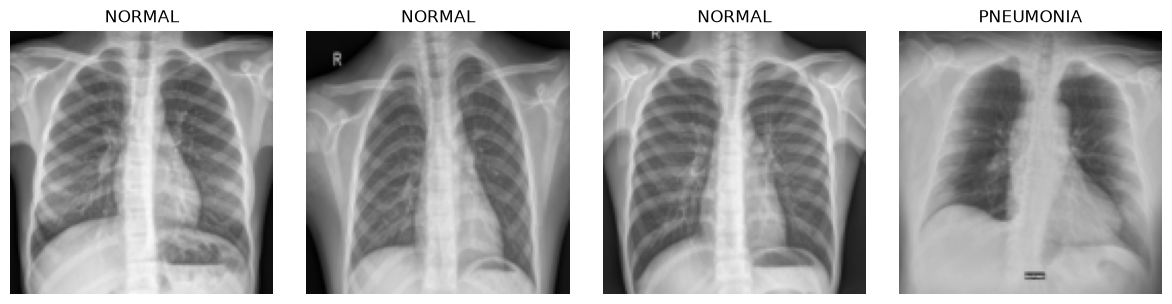

In [5]:
sample_count = min(4, len(images))
plt.figure(figsize=(12, 3))

for i in range(sample_count):
    plt.subplot(1, sample_count, i + 1)
    display_image = images[i].squeeze(0) * 0.5 + 0.5
    plt.imshow(display_image.numpy(), cmap="gray", vmin=0, vmax=1)
    plt.title(class_names[labels[i].item()])
    plt.axis("off")

plt.tight_layout()
plt.show()

## 6. Tạo CNN từ đầu

`nn.Sequential` nối các lớp theo thứ tự, không cần viết lớp model hay hàm `forward`.
`Conv2d` học bộ lọc, `ReLU` tạo tính phi tuyến, `MaxPool2d` giảm kích thước,
`Linear` đưa đặc trưng về hai điểm số của hai lớp. `Dropout` giúp hạn chế học thuộc tập train.

Model khởi tạo ngẫu nhiên, không dùng trọng số có sẵn. `B` là số ảnh trong batch.

In [6]:
model = nn.Sequential(
    # Đầu vào: [B, 1, 128, 128].
    nn.Conv2d(1, 16, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),  # [B, 16, 64, 64]

    nn.Conv2d(16, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),  # [B, 32, 32, 32]

    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),  # [B, 64, 16, 16]

    nn.AdaptiveAvgPool2d((4, 4)),  # [B, 64, 4, 4]
    nn.Flatten(),  # [B, 1024]
    nn.Linear(64 * 4 * 4, 64),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(64, 2),  # [B, 2]: hai logits, chưa có Softmax.
).to(device)

print(model)

Sequential(
  (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (7): ReLU()
  (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (9): AdaptiveAvgPool2d(output_size=(4, 4))
  (10): Flatten(start_dim=1, end_dim=-1)
  (11): Linear(in_features=1024, out_features=64, bias=True)
  (12): ReLU()
  (13): Dropout(p=0.3, inplace=False)
  (14): Linear(in_features=64, out_features=2, bias=True)
)


## 7. Tạo hàm loss

`CrossEntropyLoss` nhận trực tiếp logits và nhãn số nguyên, không đặt Softmax trước loss.
Optimizer Adam sẽ được tạo mới ở đầu ô train để mỗi lần train đều bắt đầu từ đầu.

In [7]:
loss_function = nn.CrossEntropyLoss()

## 8. Train model bằng vòng lặp `for`

Mỗi lần chạy ô này, khởi tạo lại trọng số của các lớp Conv2d/Linear và tạo optimizer Adam mới.
Vì vậy, chạy lại riêng ô train cũng học lại từ đầu, không tiếp tục từ lần trước.

Mỗi **epoch** duyệt hết tập train một lần. Mỗi batch:
**xóa gradient → dự đoán → tính loss → tính gradient → cập nhật trọng số**.

Sau mỗi epoch, chuyển sang `model.eval()` để đo validation mà không cập nhật trọng số.
Validation chỉ dùng để theo dõi. Đánh giá test và dự đoán dùng trọng số của **epoch cuối cùng**, không lưu hay nạp checkpoint.
Accuracy = số ảnh dự đoán đúng / tổng số ảnh, nằm trong [0, 1].

In [9]:
# Khởi tạo lại trọng số mỗi lần chạy ô train.
# Các lớp ReLU, Pooling, Flatten, Dropout không có trọng số cần đặt lại.
for layer in model:
    if isinstance(layer, (nn.Conv2d, nn.Linear)):
        layer.reset_parameters()

# Adam có bộ nhớ riêng, nên cũng phải tạo mới khi train lại từ đầu.
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []
epochs = 5

for epoch in range(epochs):
    # ----- TRAIN -----
    model.train()  # Bật Dropout.
    train_loss_sum = 0.0
    train_correct = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = loss_function(logits, labels)
        loss.backward()
        optimizer.step()

        predictions = logits.argmax(dim=1)
        train_loss_sum += loss.item() * images.size(0)
        train_correct += (predictions == labels).sum().item()

    # Trung bình theo số ảnh, kể cả batch cuối có ít ảnh hơn.
    train_loss = train_loss_sum / len(train_dataset)
    train_accuracy = train_correct / len(train_dataset)

    # ----- VALIDATION -----
    model.eval()  # Tắt Dropout.
    val_loss_sum = 0.0
    val_correct = 0

    with torch.no_grad():  # Không tính gradient khi đánh giá.
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)
            loss = loss_function(logits, labels)
            predictions = logits.argmax(dim=1)

            val_loss_sum += loss.item() * images.size(0)
            val_correct += (predictions == labels).sum().item()

    val_loss = val_loss_sum / len(val_dataset)
    val_accuracy = val_correct / len(val_dataset)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    print(
        f"Epoch {epoch + 1:02d}/{epochs} | "
        f"Train loss: {train_loss:.4f}, accuracy: {train_accuracy:.2%} | "
        f"Val loss: {val_loss:.4f}, accuracy: {val_accuracy:.2%}"
    )

print("Đã train xong. Đánh giá và dự đoán bằng trọng số epoch cuối:", epochs)

Epoch 01/5 | Train loss: 0.6816, accuracy: 56.78% | Val loss: 0.6201, accuracy: 93.33%
Epoch 02/5 | Train loss: 0.5460, accuracy: 87.29% | Val loss: 0.3708, accuracy: 96.67%
Epoch 03/5 | Train loss: 0.3450, accuracy: 88.14% | Val loss: 0.2187, accuracy: 96.67%
Epoch 04/5 | Train loss: 0.2362, accuracy: 88.98% | Val loss: 0.2127, accuracy: 96.67%
Epoch 05/5 | Train loss: 0.1944, accuracy: 89.83% | Val loss: 0.2097, accuracy: 96.67%
Đã train xong. Đánh giá và dự đoán bằng trọng số epoch cuối: 5


## 9. Vẽ loss và accuracy bằng `plt`

Train loss giảm nhưng validation loss tăng có thể là dấu hiệu học thuộc tập train.
Biểu đồ hiện ngay dưới ô và được lưu trong `outputs/notebook/`.

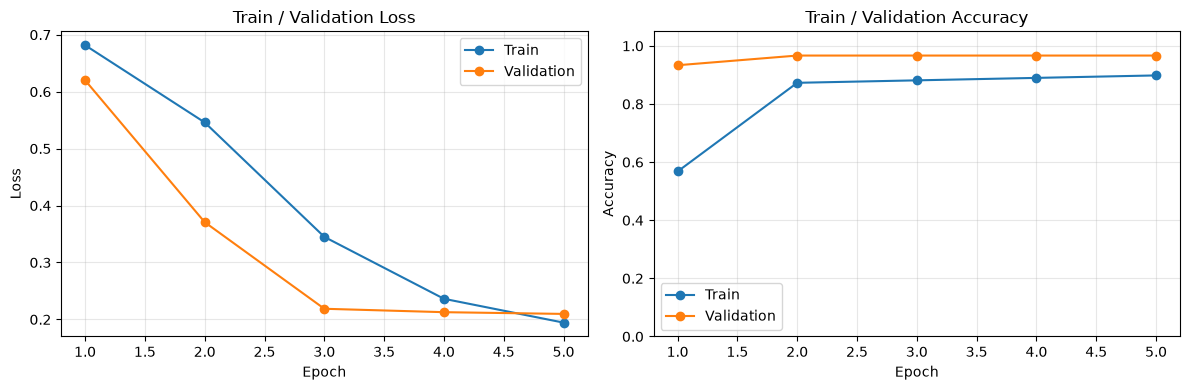

In [10]:
epoch_numbers = range(1, epochs + 1)
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epoch_numbers, train_losses, marker="o", label="Train")
plt.plot(epoch_numbers, val_losses, marker="o", label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Train / Validation Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epoch_numbers, train_accuracies, marker="o", label="Train")
plt.plot(epoch_numbers, val_accuracies, marker="o", label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Train / Validation Accuracy")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(output_dir / "training_history.png", dpi=150)
plt.show()

## 10. Đánh giá test bằng trọng số epoch cuối

Dùng trực tiếp model sau khi kết thúc vòng lặp train để đo loss và accuracy trên test.
Không nạp trọng số từ file. Tập test không dùng để cập nhật trọng số hoặc chỉnh tham số.

In [11]:
model.eval()

test_loss_sum = 0.0
test_correct = 0
true_labels = []
predicted_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        logits = model(images)
        loss = loss_function(logits, labels)
        predictions = logits.argmax(dim=1)

        test_loss_sum += loss.item() * images.size(0)
        test_correct += (predictions == labels).sum().item()
        true_labels.extend(labels.cpu().tolist())
        predicted_labels.extend(predictions.cpu().tolist())

test_loss = test_loss_sum / len(test_dataset)
test_accuracy = test_correct / len(test_dataset)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2%} ({test_correct}/{len(test_dataset)} ảnh đúng)")

Test loss: 0.1478
Test accuracy: 97.50% (39/40 ảnh đúng)


## 11. Ma trận nhầm lẫn và metric cho PNEUMONIA

**Hàng là nhãn thật**, **cột là dự đoán**. Hai ô đường chéo là dự đoán đúng.
PNEUMONIA là lớp dương tính: TP = đúng viêm phổi, FP = nhầm NORMAL thành viêm phổi,
FN = bỏ sót ảnh viêm phổi, TN = đúng NORMAL.

- Precision = TP / (TP + FP).
- Recall = TP / (TP + FN).
- F1 là trung bình điều hòa của precision và recall.

Nếu mẫu số bằng 0, đặt metric tương ứng bằng 0.

Precision: 100.00%
Recall: 95.00%
F1: 97.44%


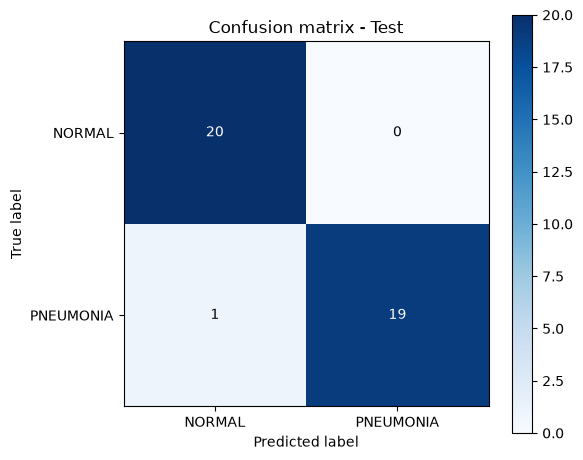

In [12]:
confusion_matrix = np.zeros((2, 2), dtype=int)
for actual, predicted in zip(true_labels, predicted_labels):
    confusion_matrix[actual, predicted] += 1

tn = int(confusion_matrix[0, 0])
fp = int(confusion_matrix[0, 1])
fn = int(confusion_matrix[1, 0])
tp = int(confusion_matrix[1, 1])

precision = tp / (tp + fp) if tp + fp > 0 else 0.0
recall = tp / (tp + fn) if tp + fn > 0 else 0.0
f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0.0

print(f"Precision: {precision:.2%}")
print(f"Recall: {recall:.2%}")
print(f"F1: {f1:.2%}")

plt.figure(figsize=(6, 5))
plt.imshow(confusion_matrix, cmap="Blues", vmin=0)
plt.colorbar()
plt.xticks([0, 1], class_names)
plt.yticks([0, 1], class_names)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Confusion matrix - Test")

for row in range(2):
    for column in range(2):
        color = "white" if confusion_matrix[row, column] > confusion_matrix.max() / 2 else "black"
        plt.text(column, row, str(confusion_matrix[row, column]),
                 ha="center", va="center", color=color)

plt.tight_layout()
plt.savefig(output_dir / "confusion_matrix.png", dpi=150)
plt.show()

## 12. Dự đoán một ảnh

Model giữ trọng số của epoch cuối cùng từ ô train. Thay `image_path` bằng ảnh muốn thử. Xử lý ảnh giống lúc train, thêm chiều batch bằng `unsqueeze(0)`.
Dùng Softmax để lấy hai điểm xác suất rồi chọn lớp có điểm lớn nhất.

Ba ảnh trong `single prediction` trùng ảnh test, chỉ dùng minh họa.
Điểm Softmax chưa được hiệu chỉnh, không diễn giải thành xác suất mắc bệnh của người trong ảnh.

Dự đoán: NORMAL
Điểm NORMAL: 84.68%
Điểm PNEUMONIA: 15.32%


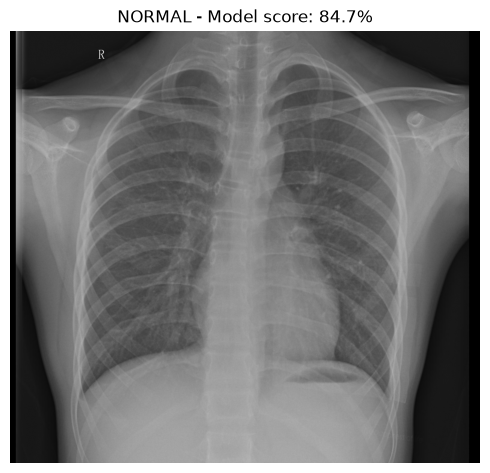

In [13]:
image_path = data_dir / "single prediction" / "normal_or_pneumonia1.jpeg"

with Image.open(image_path) as image:
    original_image = image.convert("L")
    image_tensor = transform(image)

image_tensor = image_tensor.unsqueeze(0).to(device)  # [1, 1, 128, 128]
model.eval()

with torch.no_grad():
    logits = model(image_tensor)
    probabilities = torch.softmax(logits, dim=1)[0].cpu()

predicted_label = probabilities.argmax().item()
print("Dự đoán:", class_names[predicted_label])
print(f"Điểm NORMAL: {probabilities[0].item():.2%}")
print(f"Điểm PNEUMONIA: {probabilities[1].item():.2%}")

plt.figure(figsize=(5, 5))
plt.imshow(original_image, cmap="gray")
plt.title(f"{class_names[predicted_label]} - Model score: {probabilities[predicted_label].item():.1%}")
plt.axis("off")
plt.tight_layout()
plt.savefig(output_dir / "prediction.png", dpi=150)
plt.show()

## Giới hạn của bài tập

Tập test chỉ có 40 ảnh: thay đổi một dự đoán làm accuracy đổi 2.5 điểm phần trăm.
Phép chia train/validation dựa trên ảnh, không có bảng mã bệnh nhân để bảo đảm tách theo người.
Một số tên ảnh gợi ý chuỗi chụp nhiều thời điểm của cùng ca. Khi nghiên cứu nghiêm túc,
cần kiểm tra nguồn, nhãn và chia theo bệnh nhân để tránh rò rỉ dữ liệu.

Tên thư mục có `covid19` nhưng notebook chỉ học NORMAL/PNEUMONIA, không xác định nguyên nhân viêm phổi.
Seed cố định giúp tái hiện phép chia; kết quả có thể khác giữa phần cứng và phiên bản thư viện.